# Early and Explainable Student Performance Prediction (OULAD)
### Multidimensional Academic and Behavioral Features → Early Risk Prediction → Explanation → Intervention

**Pipeline (novelty is unchanged):**

`Early-semester data → ML → Predict future performance → Identify risk → Explain why → Suggest intervention`

**Dataset:** Open University Learning Analytics Dataset (OULAD) – ~32,000 student–course enrolments with demographics, daily VLE (online platform) click logs, assessment submissions and the final result.

**Four feature dimensions (the "multidimensional" part), all built only from the first *t* days of the course:**
1. **Student profile** – prior attempts, credits, education level, deprivation band, …
2. **Course context** – module, semester, registration timing
3. **Behavioral engagement** – clicks, active days, gaps, recency, activity-type mix (VLE logs)
4. **Academic progress** – submitted / missed / late assessments and scores *so far*

**Risk label (from the final outcome, used only as ground truth):** High Risk = Fail or Withdrawn, Medium Risk = Pass, Low Risk = Distinction.

**Leakage controls**
- Every feature uses only events with `date <= t` (default t = 28 days). Nothing from after the cut-off is used.
- Students who had already un-registered before day *t* are removed (their withdrawal is already known, so it is not a prediction).
- `final_result` is used only to create the label. The same student never appears in both train and test (group split on `id_student`).
- Model selection uses cross-validation on the training set only, not the test set.

## 1. Imports and configuration

In [8]:
import io, zipfile, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import StratifiedGroupKFold, cross_val_score, cross_val_predict
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, QuantileTransformer
from sklearn.feature_selection import mutual_info_classif
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import (RandomForestClassifier, ExtraTreesClassifier,
                              HistGradientBoostingClassifier, VotingClassifier)
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             balanced_accuracy_score, classification_report,
                             confusion_matrix, roc_auc_score, roc_curve, auc,
                             fbeta_score)

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

RANDOM_STATE   = 42
PRIMARY_WINDOW = 28                    # days of course data available to the early-warning model
WINDOWS        = [0, 14, 28, 56, 84]   # used for the "how early can we warn?" analysis
MAX_WINDOW     = max(WINDOWS + [PRIMARY_WINDOW])
CV_FOLDS       = 5                     # lower to 3 for a faster run

DATA_DIR = Path("oulad_data")
OUT_DIR  = Path("outputs"); OUT_DIR.mkdir(exist_ok=True)

risk_order = ["High Risk", "Medium Risk", "Low Risk"]
KEYS = ["code_module", "code_presentation", "id_student"]

## 2. Get the OULAD data

The cell below (a) looks for the CSV files in `oulad_data/`, (b) tries to download the official zip, and (c) falls back to a file-upload prompt (Google Colab).
Official page: https://analyse.kmi.open.ac.uk/open_dataset  (also mirrored on Kaggle as *Open University Learning Analytics Dataset*).
Required files: `studentInfo.csv, studentRegistration.csv, studentAssessment.csv, assessments.csv, studentVle.csv, vle.csv`.

In [9]:
REQUIRED = ["studentInfo.csv", "studentRegistration.csv", "studentAssessment.csv",
            "assessments.csv", "studentVle.csv", "vle.csv"]
OULAD_URL = "https://analyse.kmi.open.ac.uk/open_dataset/download"

def locate_files():
    found = {}
    if DATA_DIR.exists():
        for p in DATA_DIR.rglob("*.csv"):
            found[p.name] = p
    return found

def missing(found):
    return [f for f in REQUIRED if f not in found]

def try_download():
    import requests
    DATA_DIR.mkdir(exist_ok=True)
    zpath = DATA_DIR / "oulad.zip"
    print("Downloading OULAD (about 100 MB) ...")
    with requests.get(OULAD_URL, stream=True, timeout=180) as r:
        r.raise_for_status()
        with open(zpath, "wb") as f:
            for chunk in r.iter_content(1 << 20):
                f.write(chunk)
    with zipfile.ZipFile(zpath) as z:
        z.extractall(DATA_DIR)

def upload_fallback():
    from google.colab import files          # only exists in Colab
    DATA_DIR.mkdir(exist_ok=True)
    print("Please upload the OULAD zip file or the individual CSV files.")
    for name, data in files.upload().items():
        (DATA_DIR / name).write_bytes(data)
        if name.lower().endswith(".zip"):
            with zipfile.ZipFile(DATA_DIR / name) as z:
                z.extractall(DATA_DIR)

found = locate_files()
if missing(found):
    try:
        try_download()
    except Exception as e:
        print("Automatic download failed:", repr(e))
    found = locate_files()
if missing(found):
    try:
        upload_fallback()
    except Exception as e:
        print("Upload fallback unavailable:", repr(e))
    found = locate_files()

still = missing(found)
if still:
    raise FileNotFoundError(f"Missing OULAD files: {still}. Put them in '{DATA_DIR}/' and re-run.")
print("All required OULAD files found.")

Automatic download failed: BadZipFile('File is not a zip file')
Please upload the OULAD zip file or the individual CSV files.


Saving open+university+learning+analytics+dataset.zip to open+university+learning+analytics+dataset.zip
All required OULAD files found.


## 3. Load the tables

In [10]:
NA = ["?", "", " ", "NA", "NaN"]          # the official OULAD files use '?' for missing values
def num(df, cols):
    for c in cols:
        df[c] = pd.to_numeric(df[c], errors="coerce")
    return df

info   = pd.read_csv(found["studentInfo.csv"], na_values=NA).drop_duplicates(KEYS).reset_index(drop=True)
reg    = num(pd.read_csv(found["studentRegistration.csv"], na_values=NA).drop_duplicates(KEYS),
             ["date_registration", "date_unregistration"])
assess = num(pd.read_csv(found["assessments.csv"], na_values=NA), ["date", "weight"])
sa     = num(pd.read_csv(found["studentAssessment.csv"], na_values=NA),
             ["date_submitted", "score", "is_banked"])
vle    = pd.read_csv(found["vle.csv"], na_values=NA)

vle_log = pd.read_csv(
    found["studentVle.csv"], na_values=NA,
    usecols=["code_module", "code_presentation", "id_student", "id_site", "date", "sum_click"],
    dtype={"code_module": "category", "code_presentation": "category",
           "id_student": "int32", "id_site": "int32", "date": "int16", "sum_click": "int16"})

print("studentInfo        :", info.shape)
print("studentRegistration:", reg.shape)
print("assessments        :", assess.shape)
print("studentAssessment  :", sa.shape)
print("vle (site metadata):", vle.shape)
print("studentVle (clicks):", vle_log.shape)
display(info.head())

studentInfo        : (32593, 12)
studentRegistration: (32593, 5)
assessments        : (206, 6)
studentAssessment  : (173912, 5)
vle (site metadata): (6364, 6)
studentVle (clicks): (10655280, 6)


,code_module,code_presentation,id_student,gender,region,highest_education,imd_band,age_band,num_of_prev_attempts,studied_credits,disability,final_result
0,AAA,2013J,11391,M,East Anglian Region,HE Qualification,90-100%,55<=,0,240,N,Pass
1,AAA,2013J,28400,F,Scotland,HE Qualification,20-30%,35-55,0,60,N,Pass
2,AAA,2013J,30268,F,North Western Region,A Level or Equivalent,30-40%,35-55,0,60,Y,Withdrawn
3,AAA,2013J,31604,F,South East Region,A Level or Equivalent,50-60%,35-55,0,60,N,Pass
4,AAA,2013J,32885,F,West Midlands Region,Lower Than A Level,50-60%,0-35,0,60,N,Pass


## 4. Ground-truth risk label (from the final result only)

final_result
Pass           12361
Withdrawn      10156
Fail            7052
Distinction     3024
Name: count, dtype: int64 

risk
High Risk      17208
Medium Risk    12361
Low Risk        3024
Name: count, dtype: int64


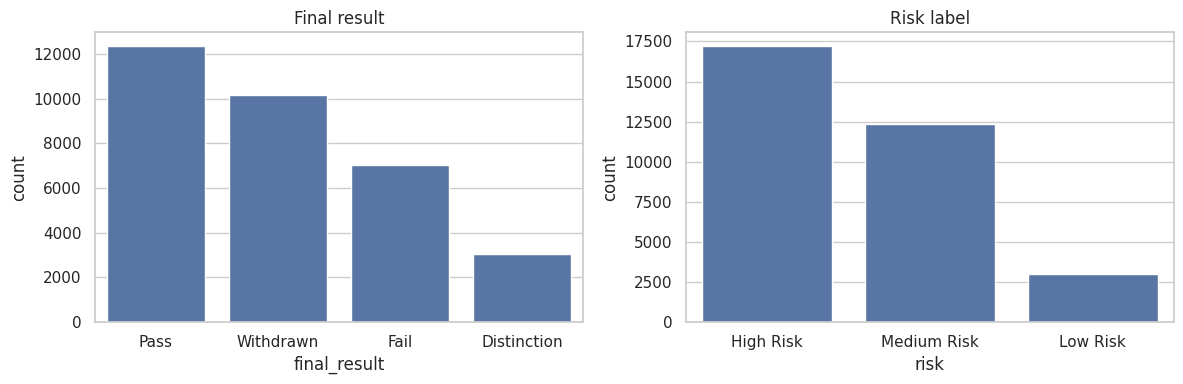

In [11]:
def risk_label(result):
    if result in ("Withdrawn", "Fail"):
        return "High Risk"
    if result == "Pass":
        return "Medium Risk"
    return "Low Risk"                       # Distinction

info["risk"] = info["final_result"].apply(risk_label)
info["skey"] = np.arange(len(info))         # unique enrolment id (module + presentation + student)

print(info["final_result"].value_counts(), "\n")
print(info["risk"].value_counts())

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.countplot(data=info, x="final_result", ax=ax[0]); ax[0].set_title("Final result")
sns.countplot(data=info, x="risk", order=risk_order, ax=ax[1]); ax[1].set_title("Risk label")
plt.tight_layout(); plt.show()

## 5. Prepare the event tables (time-stamped, so any cut-off *t* can be applied)

All event tables get the enrolment id `skey`. Only click events up to `MAX_WINDOW` days are kept (saves memory; later days are never needed).

In [12]:
key_map = info[KEYS + ["skey"]].copy()

# ---- VLE click logs ------------------------------------------------------------------
vle_log = vle_log[vle_log["date"] <= MAX_WINDOW]
for c in ["code_module", "code_presentation"]:                 # same dtype -> fast merge
    key_map[c] = key_map[c].astype(vle_log[c].dtype)
vle_log = vle_log.merge(key_map, on=KEYS, how="inner")[["skey", "id_site", "date", "sum_click"]]

TOP_TYPES = (vle.merge(vle_log.groupby("id_site")["sum_click"].sum().rename("clk"),
                       left_on="id_site", right_index=True)
                .groupby("activity_type")["clk"].sum().sort_values(ascending=False).head(8).index.tolist())
site2type = vle.set_index("id_site")["activity_type"]
vle_log["atype"] = vle_log["id_site"].map(site2type).where(lambda s: s.isin(TOP_TYPES), "other")
vle_log["atype"] = vle_log["atype"].astype("category")
vle_log["sum_click"] = vle_log["sum_click"].astype("int32")
print("Top activity types:", TOP_TYPES)
print("VLE events kept:", len(vle_log))

# ---- Assessment submissions (non-exam only: exams happen at the very end) ------------
key_map_obj = info[KEYS + ["skey"]]
assess_small = assess[["id_assessment", "code_module", "code_presentation",
                       "assessment_type", "date", "weight"]].rename(columns={"date": "due_date"})
sa_full = (sa.merge(assess_small, on="id_assessment", how="inner")
             .merge(key_map_obj, on=KEYS, how="inner"))
sa_full = sa_full[sa_full["assessment_type"] != "Exam"].copy()
assess_nonexam = assess[assess["assessment_type"] != "Exam"].copy()
print("Assessment submissions kept:", len(sa_full))

Top activity types: ['oucontent', 'forumng', 'homepage', 'quiz', 'subpage', 'resource', 'url', 'ouwiki']
VLE events kept: 5268730
Assessment submissions kept: 168953


## 6. Early-warning feature extraction

`build_features(t)` creates the four feature dimensions using **only information available on day *t***.

In [13]:
EDU_ORDER = {"No Formal quals": 0, "Lower Than A Level": 1, "A Level or Equivalent": 2,
             "HE Qualification": 3, "Post Graduate Qualification": 4}
AGE_ORDER = {"0-35": 0, "35-55": 1, "55<=": 2}

def imd_to_level(s):
    if pd.isna(s): return np.nan
    return float(str(s).replace("%", "").split("-")[0]) / 10.0      # 0 = most deprived ... 9 = least

PROFILE    = ["gender", "region", "disability", "imd_level", "edu_level", "age_level",
              "num_of_prev_attempts", "studied_credits"]
CONTEXT    = ["code_module", "semester", "date_registration"]
ENGAGEMENT = (["total_clicks", "active_days", "n_sites", "clicks_per_active_day",
               "first_active_day", "days_since_last_active", "max_gap_days",
               "pre_course_clicks", "clicks_last_7d", "clicks_last_14d", "recent_click_share"]
              + [f"clicks_{t}" for t in TOP_TYPES + ["other"]])
ASSESSMENT = ["n_assess_due", "n_submitted", "n_submitted_due", "n_missed", "submit_rate",
              "n_late", "n_low_scores", "avg_score", "min_score", "last_score",
              "weighted_score", "avg_days_early", "has_submission"]
FEATURE_COLS = PROFILE + CONTEXT + ENGAGEMENT + ASSESSMENT
CAT_COLS = ["gender", "region", "disability", "code_module", "semester"]
GROUPS = {"Student profile": PROFILE, "Course context": CONTEXT,
          "Behavioral engagement": ENGAGEMENT, "Academic progress": ASSESSMENT}

def build_features(t):
    # ---- cohort: students still registered on day t ----------------------------------
    base = info.merge(reg[KEYS + ["date_registration", "date_unregistration"]], on=KEYS, how="left")
    C = base[base["date_unregistration"].isna() | (base["date_unregistration"] > t)].copy()

    C["imd_level"]  = C["imd_band"].apply(imd_to_level)
    C["edu_level"]  = C["highest_education"].map(EDU_ORDER)
    C["age_level"]  = C["age_band"].map(AGE_ORDER)
    C["semester"]   = C["code_presentation"].str[-1]

    # ---- behavioral engagement (VLE) ---------------------------------------------------
    v = vle_log[vle_log["date"] <= t]
    g = v.groupby("skey")
    vf = g.agg(total_clicks=("sum_click", "sum"), active_days=("date", "nunique"),
               n_sites=("id_site", "nunique"), first_active_day=("date", "min"),
               last_day=("date", "max"))
    vf["pre_course_clicks"] = v[v["date"] < 0].groupby("skey")["sum_click"].sum()
    vf["clicks_last_7d"]    = v[v["date"] > t - 7].groupby("skey")["sum_click"].sum()
    vf["clicks_last_14d"]   = v[v["date"] > t - 14].groupby("skey")["sum_click"].sum()
    d = v[["skey", "date"]].drop_duplicates().sort_values(["skey", "date"])
    d["gap"] = d.groupby("skey")["date"].diff()
    vf["max_gap_days"] = d.groupby("skey")["gap"].max()
    piv = (v.groupby(["skey", "atype"], observed=True)["sum_click"].sum().unstack(fill_value=0)
             .reindex(columns=TOP_TYPES + ["other"], fill_value=0))
    piv.columns = [f"clicks_{c}" for c in piv.columns]
    vf = vf.join(piv)

    C = C.merge(vf, left_on="skey", right_index=True, how="left")
    zero_cols = ["total_clicks", "active_days", "n_sites", "pre_course_clicks",
                 "clicks_last_7d", "clicks_last_14d"] + list(piv.columns)
    C[zero_cols] = C[zero_cols].fillna(0)
    C["days_since_last_active"] = (t - C["last_day"]).fillna(t + 30)
    C["first_active_day"]       = C["first_active_day"].fillna(t + 1)
    C["max_gap_days"]           = C["max_gap_days"].fillna(t + 30)
    C["clicks_per_active_day"]  = C["total_clicks"] / C["active_days"].replace(0, np.nan)
    C["clicks_per_active_day"]  = C["clicks_per_active_day"].fillna(0)
    C["recent_click_share"]     = (C["clicks_last_14d"] / C["total_clicks"].replace(0, np.nan)).fillna(0)

    # ---- academic progress (assessments due / submitted on or before day t) ------------
    due = assess_nonexam[assess_nonexam["date"] <= t]
    nd = (due.groupby(["code_module", "code_presentation"])
             .agg(n_assess_due=("id_assessment", "count")).reset_index())
    C = C.merge(nd, on=["code_module", "code_presentation"], how="left")
    C["n_assess_due"] = C["n_assess_due"].fillna(0)

    s = sa_full[sa_full["date_submitted"] <= t].copy()
    s["late"]        = (s["date_submitted"] > s["due_date"]).astype(int)
    s["days_early"]  = s["due_date"] - s["date_submitted"]
    s["low"]         = (s["score"] < 40).astype(int)
    s["w_score"]     = s["score"] * s["weight"]
    gs = s.groupby("skey")
    af = gs.agg(n_submitted=("id_assessment", "count"), avg_score=("score", "mean"),
                min_score=("score", "min"), n_late=("late", "sum"),
                n_low_scores=("low", "sum"), avg_days_early=("days_early", "mean"))
    af["weighted_score"] = gs["w_score"].sum() / gs["weight"].sum().replace(0, np.nan)
    af["last_score"] = s.sort_values("date_submitted").groupby("skey")["score"].last()
    af["n_submitted_due"] = s[s["due_date"] <= t].groupby("skey").size()

    C = C.merge(af, left_on="skey", right_index=True, how="left")
    for c in ["n_submitted", "n_late", "n_low_scores", "n_submitted_due"]:
        C[c] = C[c].fillna(0)
    C["n_missed"]       = (C["n_assess_due"] - C["n_submitted_due"]).clip(lower=0)
    C["submit_rate"]    = (C["n_submitted_due"] / C["n_assess_due"].replace(0, np.nan)).clip(upper=1)
    C["has_submission"] = (C["n_submitted"] > 0).astype(int)

    meta = ["skey", "id_student", "code_presentation", "final_result", "risk"]
    D = C[meta + FEATURE_COLS].set_index("skey", drop=False)
    return D

D = build_features(PRIMARY_WINDOW)
print(f"Feature table at day {PRIMARY_WINDOW}:", D.shape)
print("Students dropped because they had already un-registered:", len(info) - len(D))
print(D["risk"].value_counts())
display(D[FEATURE_COLS].describe().T.head(25))

Feature table at day 28: (27538, 49)
Students dropped because they had already un-registered: 5055
risk
Medium Risk    12361
High Risk      12153
Low Risk        3024
Name: count, dtype: int64


,count,mean,std,min,25%,50%,75%,max
imd_level,26510.0,4.299661,2.813487,0.0,2.000000,4.000000,7.000000,9.0
edu_level,27538.0,1.760585,0.751765,0.0,1.000000,2.000000,2.000000,4.0
age_level,27538.0,0.310553,0.477635,0.0,0.000000,0.000000,1.000000,2.0
num_of_prev_attempts,27538.0,0.160033,0.472881,0.0,0.000000,0.000000,0.000000,6.0
studied_credits,27538.0,76.355945,38.274708,30.0,60.000000,60.000000,90.000000,630.0
date_registration,27531.0,-66.387636,47.619251,-311.0,-95.000000,-53.000000,-29.000000,167.0
total_clicks,27538.0,356.744426,430.857358,0.0,90.000000,225.000000,470.000000,7697.0
active_days,27538.0,14.648232,10.358609,0.0,7.000000,13.000000,21.000000,54.0
n_sites,27538.0,29.113988,22.076357,0.0,13.250000,23.000000,41.000000,285.0
clicks_per_active_day,27538.0,20.493321,14.115017,0.0,11.230769,17.812500,26.866667,197.0


## 7. Train / test split (grouped by student – no student in both sets)

In [14]:
sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
tr_i, te_i = next(sgkf.split(info, info["risk"], groups=info["id_student"]))
train_ids = set(info["id_student"].iloc[tr_i])
test_ids  = set(info["id_student"].iloc[te_i])
assert train_ids.isdisjoint(test_ids)

def split(Dw):
    tr = Dw["id_student"].isin(train_ids)
    return Dw[tr], Dw[~tr]

D_train, D_test = split(D)
X_train, y_train = D_train[FEATURE_COLS], D_train["risk"]
X_test,  y_test  = D_test[FEATURE_COLS],  D_test["risk"]
groups_train = D_train["id_student"]

print("Train:", X_train.shape, "| Test:", X_test.shape)
print("\nTrain risk distribution:\n", y_train.value_counts())
print("\nTest risk distribution:\n", y_test.value_counts())

Train: (21959, 44) | Test: (5579, 44)

Train risk distribution:
 risk
Medium Risk    9843
High Risk      9716
Low Risk       2400
Name: count, dtype: int64

Test risk distribution:
 risk
Medium Risk    2518
High Risk      2437
Low Risk        624
Name: count, dtype: int64


## 8. Helpers: preprocessing, models, and evaluation

`proba_in_order` always returns probabilities in the order **High, Medium, Low**. (sklearn orders classes alphabetically, which is High, Low, Medium – using it without re-ordering silently mismatches ROC-AUC and per-class curves.)

In [15]:
def make_preprocessor(columns):
    num = [c for c in columns if c not in CAT_COLS]
    cat = [c for c in columns if c in CAT_COLS]
    steps = []
    if num:
        steps.append(("num", Pipeline([
            ("imp", SimpleImputer(strategy="median")),
            ("qt",  QuantileTransformer(n_quantiles=200, output_distribution="normal",
                                        random_state=RANDOM_STATE))]), num))
    if cat:
        steps.append(("cat", Pipeline([
            ("imp", SimpleImputer(strategy="most_frequent")),
            ("oh",  OneHotEncoder(handle_unknown="ignore", sparse_output=False))]), cat))
    return ColumnTransformer(steps)

def base_models():
    return {
        "Logistic Regression": LogisticRegression(max_iter=3000, C=0.5, class_weight="balanced"),
        "Random Forest": RandomForestClassifier(n_estimators=300, min_samples_leaf=5,
                            class_weight="balanced_subsample", n_jobs=-1, random_state=RANDOM_STATE),
        "Extra Trees": ExtraTreesClassifier(n_estimators=300, min_samples_leaf=5,
                            class_weight="balanced", n_jobs=-1, random_state=RANDOM_STATE),
        "HistGradientBoosting": HistGradientBoostingClassifier(max_iter=250, learning_rate=0.06,
                            max_leaf_nodes=15, l2_regularization=1.0, class_weight="balanced",
                            random_state=RANDOM_STATE),
    }

def make_pipeline(name, columns=None):
    columns = columns or FEATURE_COLS
    ms = base_models()
    if name == "Voting Ensemble":
        est = VotingClassifier([("hgb", ms["HistGradientBoosting"]), ("rf", ms["Random Forest"]),
                                ("lr", ms["Logistic Regression"])], voting="soft")
    else:
        est = ms[name]
    return Pipeline([("prep", make_preprocessor(columns)), ("model", est)])

MODEL_NAMES = ["Logistic Regression", "Random Forest", "Extra Trees",
               "HistGradientBoosting", "Voting Ensemble"]

def proba_in_order(model, X):
    P = model.predict_proba(X)
    idx = [list(model.classes_).index(c) for c in risk_order]
    return P[:, idx]

def labels_from_proba(P):
    return np.array(risk_order)[P.argmax(axis=1)]

def auc_ovr(y_true, P):
    # sklearn needs alphabetically sorted labels -> reorder our High/Medium/Low columns to match
    srt = sorted(risk_order)
    return roc_auc_score(y_true, P[:, [risk_order.index(c) for c in srt]],
                         multi_class="ovr", average="weighted", labels=srt)

def evaluate(y_true, P, y_pred=None):
    y_pred = labels_from_proba(P) if y_pred is None else y_pred
    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, average="weighted", zero_division=0),
        "Recall": recall_score(y_true, y_pred, average="weighted", zero_division=0),
        "F1 Score": f1_score(y_true, y_pred, average="weighted", zero_division=0),
        "Macro F1": f1_score(y_true, y_pred, average="macro", zero_division=0),
        "Balanced Accuracy": balanced_accuracy_score(y_true, y_pred),
        "ROC-AUC": auc_ovr(y_true, P),
    }

# PART A — DATA-DRIVEN RISK WEIGHTING

Mutual Information (computed on the **training set only**) gives data-driven feature weights. They are used (1) to show which dimensions matter and (2) to build the interpretable weighted-risk baseline.

In [16]:
prep_mi = make_preprocessor(FEATURE_COLS)
Xt = prep_mi.fit_transform(X_train)
mi_names = prep_mi.get_feature_names_out()
Xt = pd.DataFrame(Xt, columns=mi_names, index=X_train.index)

y_train_enc = y_train.map({c: i for i, c in enumerate(risk_order)})
sample = Xt.sample(min(10000, len(Xt)), random_state=RANDOM_STATE).index
mi_scores = mutual_info_classif(Xt.loc[sample], y_train_enc.loc[sample], random_state=RANDOM_STATE)

def raw_name(col):
    body = col.split("__", 1)[1]
    if col.startswith("cat__"):
        cands = [c for c in CAT_COLS if body.startswith(c + "_")]
        return max(cands, key=len) if cands else body
    return body

mi_df = pd.DataFrame({"Encoded_Feature": mi_names, "Feature": [raw_name(c) for c in mi_names],
                      "Mutual_Information": mi_scores})
mi_feat = mi_df.groupby("Feature", as_index=False)["Mutual_Information"].sum()
mi_feat["Weight"] = mi_feat["Mutual_Information"] / (mi_feat["Mutual_Information"].sum() + 1e-12)
dim_of = {f: d for d, fs in GROUPS.items() for f in fs}
mi_feat["Dimension"] = mi_feat["Feature"].map(dim_of)
mi_feat = mi_feat.sort_values("Weight", ascending=False).reset_index(drop=True)

display(mi_feat.head(20))
print("Total normalized weight:", round(mi_feat["Weight"].sum(), 6))
display(mi_feat.groupby("Dimension")["Weight"].sum().sort_values(ascending=False).to_frame("Total weight"))

,Feature,Mutual_Information,Weight,Dimension
0,avg_score,0.077314,0.062136,Academic progress
1,last_score,0.073994,0.059468,Academic progress
2,weighted_score,0.070257,0.056464,Academic progress
3,min_score,0.069492,0.055850,Academic progress
4,clicks_homepage,0.056802,0.045651,Behavioral engagement
5,total_clicks,0.054732,0.043987,Behavioral engagement
6,active_days,0.053016,0.042608,Behavioral engagement
7,submit_rate,0.051538,0.041420,Academic progress
8,n_missed,0.049947,0.040141,Academic progress
9,clicks_last_14d,0.043047,0.034596,Behavioral engagement


Total normalized weight: 1.0


,Total weight
Dimension,
Behavioral engagement,0.493025
Academic progress,0.389982
Student profile,0.082404
Course context,0.034589


## 9. Plot data-driven feature weights

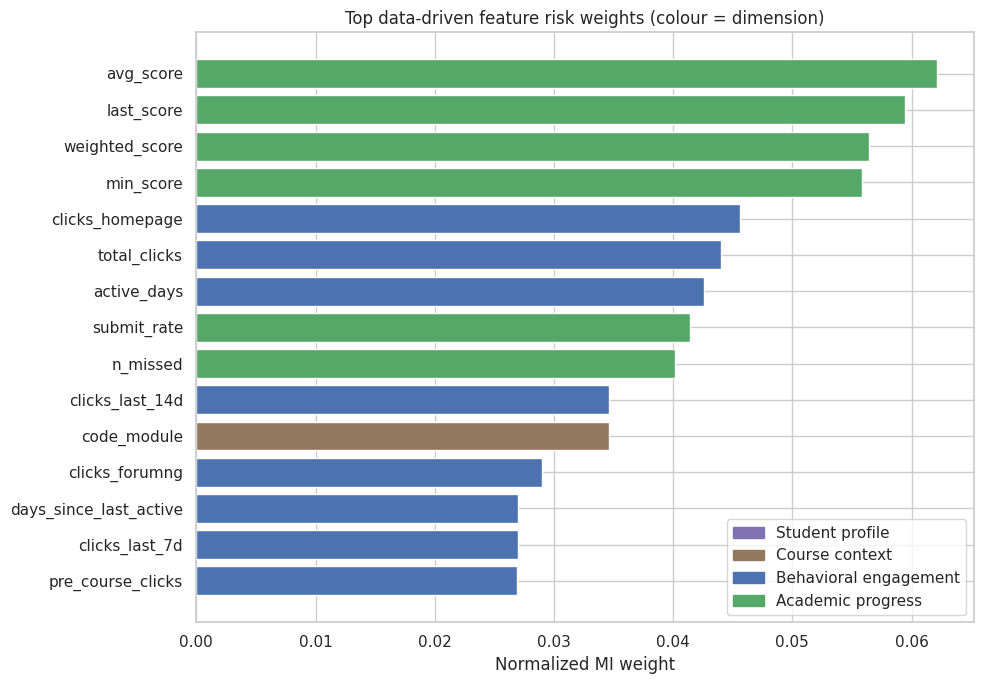

In [17]:
top_w = mi_feat.head(15).sort_values("Weight")
colors = top_w["Dimension"].map({"Student profile": "#8172B3", "Course context": "#937860",
                                 "Behavioral engagement": "#4C72B0", "Academic progress": "#55A868"})
plt.figure(figsize=(10, 7))
plt.barh(top_w["Feature"], top_w["Weight"], color=colors)
plt.xlabel("Normalized MI weight"); plt.title("Top data-driven feature risk weights (colour = dimension)")
from matplotlib.patches import Patch
plt.legend(handles=[Patch(color=c, label=l) for l, c in
           [("Student profile", "#8172B3"), ("Course context", "#937860"),
            ("Behavioral engagement", "#4C72B0"), ("Academic progress", "#55A868")]], loc="lower right")
plt.tight_layout(); plt.show()

## 10. Interpretable weighted-risk index (baseline)

Each indicator is turned into a 0–1 *risk component* using its percentile in the training data, flipped when low values mean higher risk. Components are combined with the MI weights. The two cut-offs are the training-score quantiles that match the training class proportions, so nothing is hand-tuned. Evaluated on the **test set**.

In [18]:
RISK_INDICATORS = {   # +1: higher value = higher risk, -1: lower value = higher risk
    "total_clicks": -1, "active_days": -1, "clicks_last_14d": -1,
    "days_since_last_active": +1, "max_gap_days": +1,
    "avg_score": -1, "submit_rate": -1, "n_missed": +1, "n_late": +1,
    "num_of_prev_attempts": +1, "studied_credits": +1, "imd_level": -1, "edu_level": -1,
}
ind = list(RISK_INDICATORS)
med = X_train[ind].median()
Xi = X_train[ind].fillna(med)
mi_i = pd.Series(mutual_info_classif(Xi.loc[sample], y_train_enc.loc[sample], random_state=RANDOM_STATE), index=ind)
w_i = mi_i / (mi_i.sum() + 1e-12)
ref_sorted = {f: np.sort(Xi[f].values) for f in ind}

def risk_score(df):
    score = np.zeros(len(df))
    for f, direction in RISK_INDICATORS.items():
        v = df[f].fillna(med[f]).values
        r = np.searchsorted(ref_sorted[f], v, side="right") / len(ref_sorted[f])
        score += w_i[f] * (r if direction == 1 else 1 - r)
    return score

props = y_train.value_counts(normalize=True)
s_train = risk_score(X_train)
thr_high = np.quantile(s_train, 1 - props["High Risk"])
thr_low  = np.quantile(s_train, props["Low Risk"])

def score_to_label(s):
    return np.where(s >= thr_high, "High Risk", np.where(s <= thr_low, "Low Risk", "Medium Risk"))

pred_wri = score_to_label(risk_score(X_test))
wri = {"Method": "Weighted Risk Index (test set)",
       "Accuracy": accuracy_score(y_test, pred_wri),
       "Precision": precision_score(y_test, pred_wri, average="weighted", zero_division=0),
       "Recall": recall_score(y_test, pred_wri, average="weighted", zero_division=0),
       "F1 Score": f1_score(y_test, pred_wri, average="weighted", zero_division=0),
       "Balanced Accuracy": balanced_accuracy_score(y_test, pred_wri)}
weighted_results = pd.DataFrame([wri])
display(w_i.sort_values(ascending=False).to_frame("Index weight"))
display(weighted_results)
print(classification_report(y_test, pred_wri, labels=risk_order, zero_division=0))

,Index weight
avg_score,0.204019
submit_rate,0.127107
active_days,0.124873
total_clicks,0.120543
n_missed,0.105543
days_since_last_active,0.097860
clicks_last_14d,0.086144
max_gap_days,0.065269
edu_level,0.033236
imd_level,0.020657


,Method,Accuracy,Precision,Recall,F1 Score,Balanced Accuracy
0,Weighted Risk Index (test set),0.551533,0.551909,0.551533,0.551709,0.492785


              precision    recall  f1-score   support

   High Risk       0.62      0.62      0.62      2437
 Medium Risk       0.55      0.54      0.54      2518
    Low Risk       0.31      0.31      0.31       624

    accuracy                           0.55      5579
   macro avg       0.49      0.49      0.49      5579
weighted avg       0.55      0.55      0.55      5579



# PART B — MACHINE LEARNING RISK PREDICTION

## 11. Cross-validated model selection (training set only)

In [19]:
cv = StratifiedGroupKFold(n_splits=CV_FOLDS, shuffle=True, random_state=RANDOM_STATE)
cv_splits = list(cv.split(X_train, y_train, groups=groups_train))

cv_rows = []
for name in MODEL_NAMES:
    scores = cross_val_score(make_pipeline(name), X_train, y_train, cv=cv_splits, scoring="f1_macro")
    cv_rows.append({"Model": name, "CV Macro F1": scores.mean(), "Std": scores.std()})
    print(f"{name:22s} macro-F1 = {scores.mean():.4f} ± {scores.std():.4f}")

cv_df = pd.DataFrame(cv_rows).sort_values("CV Macro F1", ascending=False).reset_index(drop=True)
display(cv_df)
best_model_name = cv_df.loc[0, "Model"]
print("\nBest model chosen by cross-validation:", best_model_name)

Logistic Regression    macro-F1 = 0.5134 ± 0.0068
Random Forest          macro-F1 = 0.5508 ± 0.0059
Extra Trees            macro-F1 = 0.5408 ± 0.0060
HistGradientBoosting   macro-F1 = 0.5283 ± 0.0023
Voting Ensemble        macro-F1 = 0.5492 ± 0.0056


,Model,CV Macro F1,Std
0,Random Forest,0.550843,0.005860
1,Voting Ensemble,0.549247,0.005558
2,Extra Trees,0.540832,0.005989
3,HistGradientBoosting,0.528289,0.002280
4,Logistic Regression,0.513363,0.006760



Best model chosen by cross-validation: Random Forest


## 12. Train all models and evaluate on the held-out test set

In [20]:
trained, rows, test_proba = {}, [], {}
for name in MODEL_NAMES:
    m = make_pipeline(name).fit(X_train, y_train)
    P = proba_in_order(m, X_test)
    trained[name], test_proba[name] = m, P
    rows.append({"Model": name, **evaluate(y_test, P)})

results_df = pd.DataFrame(rows).sort_values("Macro F1", ascending=False).reset_index(drop=True)
display(results_df.round(4))

,Model,Accuracy,Precision,Recall,F1 Score,Macro F1,Balanced Accuracy,ROC-AUC
0,Voting Ensemble,0.5822,0.6120,0.5822,0.5914,0.5470,0.5815,0.7500
1,Random Forest,0.6019,0.6100,0.6019,0.6016,0.5431,0.5381,0.7458
2,Extra Trees,0.5772,0.6089,0.5772,0.5876,0.5374,0.5637,0.7416
3,HistGradientBoosting,0.5580,0.6093,0.5580,0.5691,0.5281,0.5882,0.7456
4,Logistic Regression,0.5386,0.5952,0.5386,0.5494,0.5127,0.5809,0.7347


## 13. Compare classifier performance

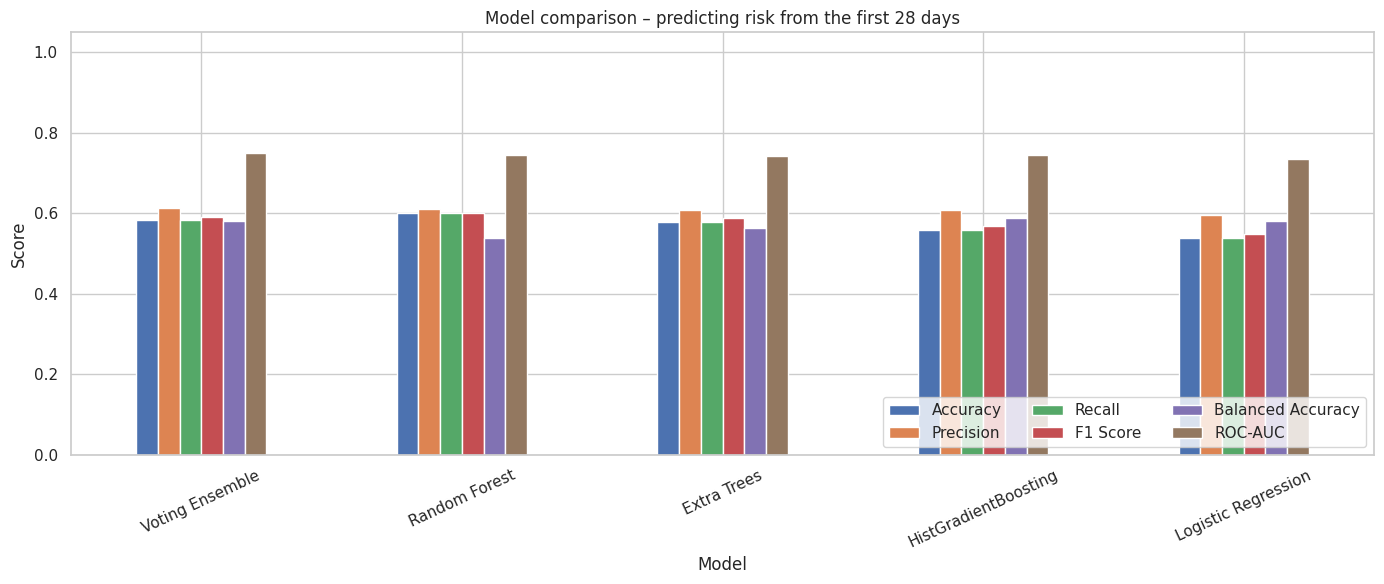

In [21]:
metrics = ["Accuracy", "Precision", "Recall", "F1 Score", "Balanced Accuracy", "ROC-AUC"]
results_df.set_index("Model")[metrics].plot(kind="bar", figsize=(14, 6))
plt.title(f"Model comparison – predicting risk from the first {PRIMARY_WINDOW} days")
plt.ylabel("Score"); plt.ylim(0, 1.05); plt.xticks(rotation=25); plt.legend(loc="lower right", ncol=3)
plt.tight_layout(); plt.show()

## 14. Best model: detailed report, confusion matrix and ROC curves

Best model: Random Forest
              precision    recall  f1-score   support

   High Risk       0.71      0.59      0.65      2437
 Medium Risk       0.57      0.67      0.62      2518
    Low Risk       0.39      0.35      0.37       624

    accuracy                           0.60      5579
   macro avg       0.56      0.54      0.54      5579
weighted avg       0.61      0.60      0.60      5579



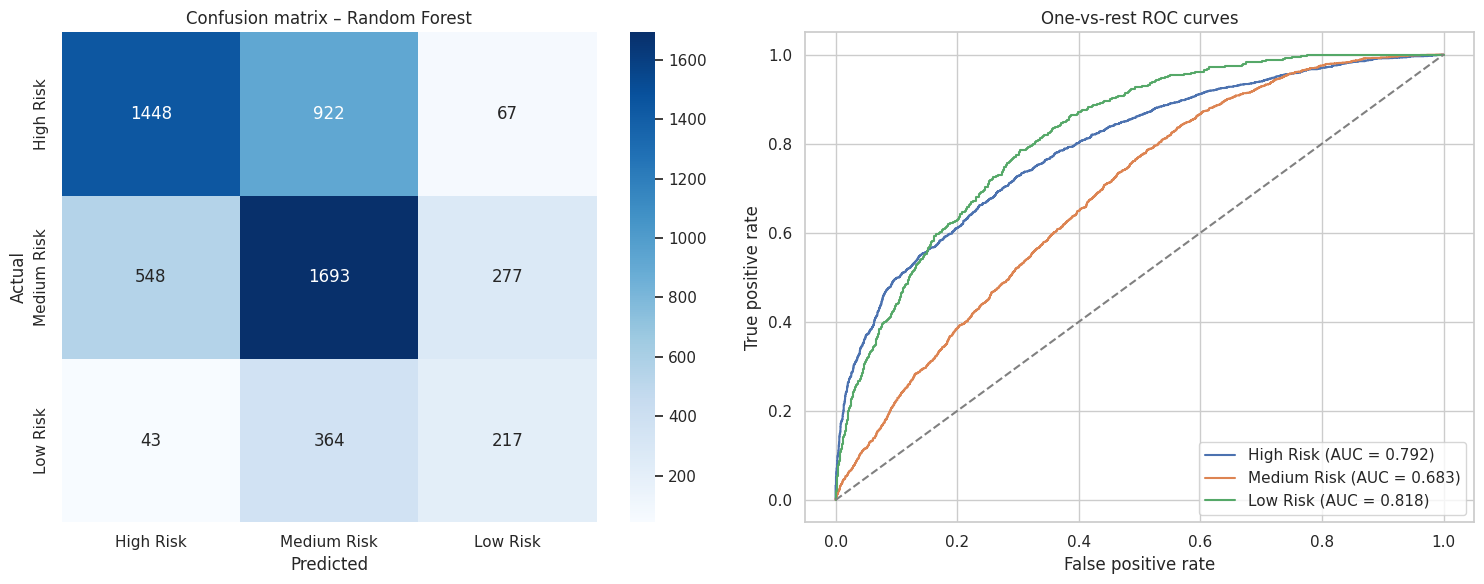

Weighted multiclass ROC-AUC: 0.7458


In [22]:
best_model = trained[best_model_name]
P_best = test_proba[best_model_name]
pred_best = labels_from_proba(P_best)

print("Best model:", best_model_name)
print(classification_report(y_test, pred_best, labels=risk_order, zero_division=0))

cm = confusion_matrix(y_test, pred_best, labels=risk_order)
fig, ax = plt.subplots(1, 2, figsize=(15, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=risk_order, yticklabels=risk_order, ax=ax[0])
ax[0].set_xlabel("Predicted"); ax[0].set_ylabel("Actual"); ax[0].set_title(f"Confusion matrix – {best_model_name}")

for i, c in enumerate(risk_order):
    fpr, tpr, _ = roc_curve((y_test == c).astype(int), P_best[:, i])
    ax[1].plot(fpr, tpr, label=f"{c} (AUC = {auc(fpr, tpr):.3f})")
ax[1].plot([0, 1], [0, 1], "--", color="grey")
ax[1].set_xlabel("False positive rate"); ax[1].set_ylabel("True positive rate")
ax[1].set_title("One-vs-rest ROC curves"); ax[1].legend()
plt.tight_layout(); plt.show()

print("Weighted multiclass ROC-AUC:", round(auc_ovr(y_test, P_best), 4))

## 15. Tune the High-Risk alert threshold (out-of-fold, training data only)

An early-warning system should rarely miss a student who is going to fail or withdraw, but flagging *everyone* is useless. High Risk is already about half of all students in OULAD, so we use a target-recall rule: pick the **highest** threshold on `P(High Risk)` whose out-of-fold recall for High Risk is at least `TARGET_RECALL` (default 85%). That keeps recall high while flagging as few students as possible. If the target cannot be reached, the threshold with the best High-Risk F1 is used. Out-of-fold predictions on the training set are used, so the test set stays untouched.

Selected threshold on P(High Risk): 0.26  (target out-of-fold recall >= 85%)


,High-Risk Precision,High-Risk Recall,High-Risk F1,Accuracy (3-class)
Default (argmax),0.7102,0.5942,0.647,0.6019
Tuned (thr=0.26),0.5670,0.8716,0.687,0.5609


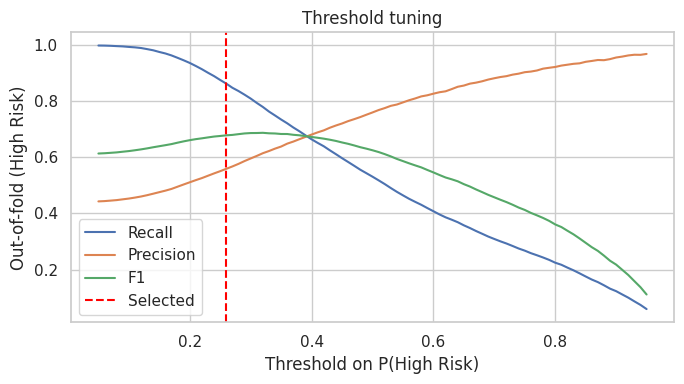

In [23]:
oof_raw = cross_val_predict(make_pipeline(best_model_name), X_train, y_train, cv=cv_splits, method="predict_proba")
cls_sorted = sorted(risk_order)                                   # order used by cross_val_predict
oof = oof_raw[:, [cls_sorted.index(c) for c in risk_order]]

def apply_threshold(P, thr):
    pred = labels_from_proba(P)
    other = np.where(P[:, 1] >= P[:, 2], "Medium Risk", "Low Risk")
    return np.where(P[:, 0] >= thr, "High Risk", np.where(pred == "High Risk", other, pred))

TARGET_RECALL = 0.85
grid = np.arange(0.05, 0.96, 0.01)
is_high = (y_train == "High Risk").values
rec, prec, f1h = [], [], []
for t_ in grid:
    p_ = apply_threshold(oof, t_) == "High Risk"
    rec.append(recall_score(is_high, p_)); prec.append(precision_score(is_high, p_, zero_division=0))
    f1h.append(f1_score(is_high, p_, zero_division=0))
ok = [g for g, r in zip(grid, rec) if r >= TARGET_RECALL]
best_thr = float(max(ok)) if ok else float(grid[int(np.argmax(f1h))])
print(f"Selected threshold on P(High Risk): {best_thr:.2f}  (target out-of-fold recall >= {TARGET_RECALL:.0%})")

pred_tuned = apply_threshold(P_best, best_thr)
def high_stats(pred):
    t, p = (y_test == "High Risk"), (pred == "High Risk")
    return {"High-Risk Precision": precision_score(t, p), "High-Risk Recall": recall_score(t, p),
            "High-Risk F1": f1_score(t, p), "Accuracy (3-class)": accuracy_score(y_test, pred)}
thr_cmp = pd.DataFrame({"Default (argmax)": high_stats(pred_best),
                        f"Tuned (thr={best_thr:.2f})": high_stats(pred_tuned)}).T
display(thr_cmp.round(4))

plt.figure(figsize=(7, 4))
plt.plot(grid, rec, label="Recall"); plt.plot(grid, prec, label="Precision"); plt.plot(grid, f1h, label="F1")
plt.axvline(best_thr, ls="--", color="red", label="Selected")
plt.xlabel("Threshold on P(High Risk)"); plt.ylabel("Out-of-fold (High Risk)"); plt.title("Threshold tuning"); plt.legend()
plt.tight_layout(); plt.show()

## 16. How early can we warn? Performance vs. observation window

The same pipeline is re-built using only the first *t* days of data. This is the core "early" claim: the model already works well after a few weeks, and keeps improving as more evidence arrives.
(The set of students differs slightly by window because students who already un-registered before day *t* are removed.)

,Window (days),Students,Accuracy,Macro F1,Balanced Accuracy,ROC-AUC
0,0,29496,0.4923,0.4549,0.5207,0.6800
1,14,28119,0.5066,0.4746,0.5385,0.7018
2,28,27538,0.5580,0.5281,0.5882,0.7456
3,56,26522,0.6117,0.5865,0.6457,0.7886
4,84,25724,0.6491,0.6268,0.6840,0.8142


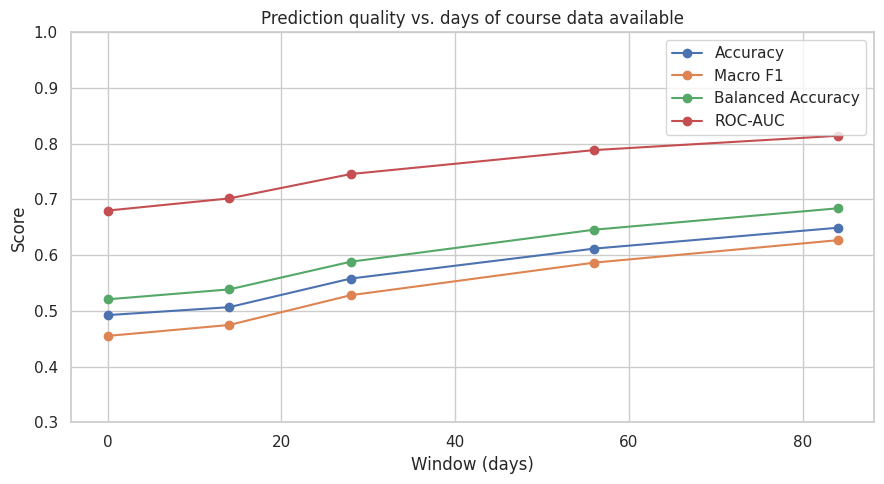

In [24]:
win_rows, window_data = [], {}
for t in WINDOWS:
    Dw = D if t == PRIMARY_WINDOW else build_features(t)
    window_data[t] = Dw
    tr, te = split(Dw)
    m = make_pipeline("HistGradientBoosting").fit(tr[FEATURE_COLS], tr["risk"])
    P = proba_in_order(m, te[FEATURE_COLS])
    r = evaluate(te["risk"], P)
    win_rows.append({"Window (days)": t, "Students": len(Dw), **{k: r[k] for k in ["Accuracy", "Macro F1", "Balanced Accuracy", "ROC-AUC"]}})
win_df = pd.DataFrame(win_rows)
display(win_df.round(4))

win_df.set_index("Window (days)")[["Accuracy", "Macro F1", "Balanced Accuracy", "ROC-AUC"]].plot(marker="o", figsize=(9, 5))
plt.title("Prediction quality vs. days of course data available"); plt.ylabel("Score"); plt.ylim(0.3, 1.0)
plt.tight_layout(); plt.show()

## 17. Does the multidimensional design help? (feature-dimension ablation)

Models trained on one dimension alone, on pairs, and on everything – same split, same learner.

,Feature set,#Features,Accuracy,Macro F1,Balanced Accuracy,ROC-AUC
0,Student profile only,8,0.4063,0.3829,0.4535,0.5959
1,Behavioral engagement only,20,0.4954,0.4592,0.5080,0.6776
2,Academic progress only,13,0.4676,0.4525,0.5373,0.6956
3,Profile + Context,11,0.4429,0.4174,0.4812,0.6255
4,Engagement + Academic,33,0.5402,0.5100,0.5684,0.7292
5,ALL four dimensions,44,0.5580,0.5281,0.5882,0.7456


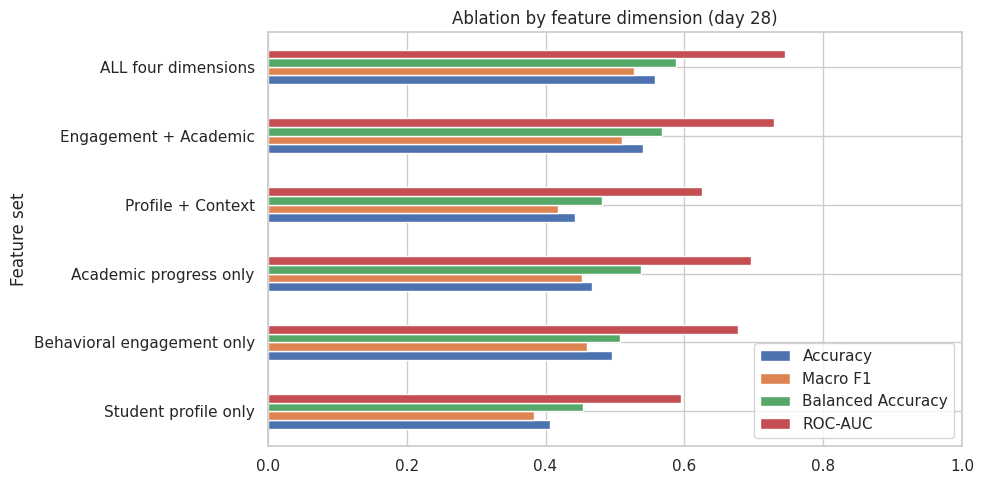

In [25]:
combos = {
    "Student profile only":                 ["Student profile"],
    "Behavioral engagement only":           ["Behavioral engagement"],
    "Academic progress only":               ["Academic progress"],
    "Profile + Context":                    ["Student profile", "Course context"],
    "Engagement + Academic":                ["Behavioral engagement", "Academic progress"],
    "ALL four dimensions":                  list(GROUPS),
}
ab_rows = []
for label, dims in combos.items():
    cols = [c for d in dims for c in GROUPS[d]]
    m = make_pipeline("HistGradientBoosting", cols).fit(X_train[cols], y_train)
    r = evaluate(y_test, proba_in_order(m, X_test[cols]))
    ab_rows.append({"Feature set": label, "#Features": len(cols), "Accuracy": r["Accuracy"],
                    "Macro F1": r["Macro F1"], "Balanced Accuracy": r["Balanced Accuracy"], "ROC-AUC": r["ROC-AUC"]})
ab_df = pd.DataFrame(ab_rows)
display(ab_df.round(4))
ab_df.set_index("Feature set")[["Accuracy", "Macro F1", "Balanced Accuracy", "ROC-AUC"]].plot(kind="barh", figsize=(10, 5))
plt.title(f"Ablation by feature dimension (day {PRIMARY_WINDOW})"); plt.xlim(0, 1); plt.tight_layout(); plt.show()

## 18. Robustness: train on earlier presentations, test on later ones (temporal validation)

Trained on 2013 course runs and tested on 2014 runs (students seen in training are removed from the test set).

In [27]:
yr = D["code_presentation"].str[:4]
tr_t = D[yr == "2013"]
te_t = D[(yr == "2014") & (~D["id_student"].isin(set(tr_t["id_student"])))]
if len(tr_t) > 100 and len(te_t) > 100:
    m = make_pipeline("HistGradientBoosting").fit(tr_t[FEATURE_COLS], tr_t["risk"])
    r = evaluate(te_t["risk"], proba_in_order(m, te_t[FEATURE_COLS]))
    print(f"Train: {len(tr_t)} students (2013)  |  Test: {len(te_t)} students (2014)")
    display(pd.DataFrame([r]).round(4))
else:
    print("Not enough 2013/2014 data in the loaded files for a temporal split.")

Train: 11809 students (2013)  |  Test: 14264 students (2014)


,Accuracy,Precision,Recall,F1 Score,Macro F1,Balanced Accuracy,ROC-AUC
0,0.5285,0.5599,0.5285,0.5326,0.4973,0.5343,0.7151


# PART C — EXPLAIN WHY, THEN SUGGEST INTERVENTION

## 19. Global explanation: which features and which dimensions drive the predictions?

,Feature,Importance,Std,Dimension
0,avg_score,0.013245,0.002070,Academic progress
1,min_score,0.009773,0.003000,Academic progress
2,code_module,0.009284,0.001393,Course context
3,weighted_score,0.008258,0.001318,Academic progress
4,last_score,0.006352,0.001493,Academic progress
5,edu_level,0.005067,0.002947,Student profile
6,date_registration,0.003350,0.000914,Course context
7,total_clicks,0.003272,0.001327,Behavioral engagement
8,clicks_forumng,0.003234,0.001779,Behavioral engagement
9,semester,0.002996,0.000786,Course context


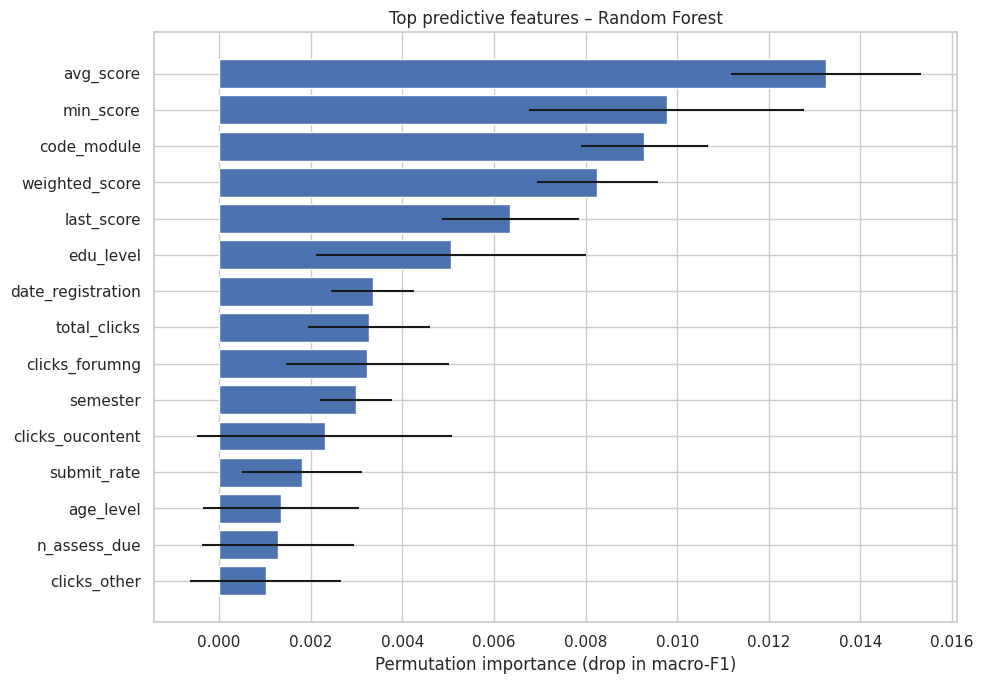

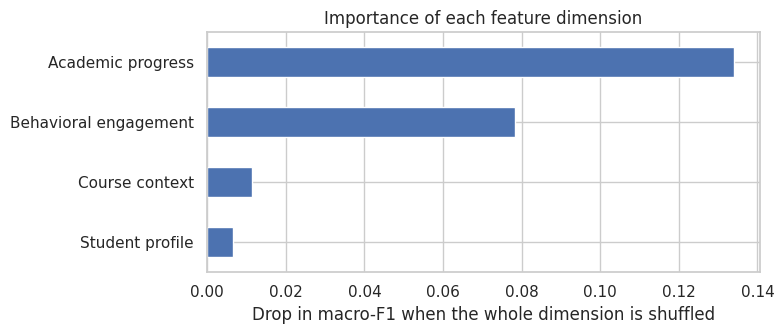

In [28]:
from sklearn.inspection import permutation_importance
rng = np.random.RandomState(RANDOM_STATE)
sub = X_test.sample(min(4000, len(X_test)), random_state=RANDOM_STATE)
y_sub = y_test.loc[sub.index]

perm = permutation_importance(best_model, sub, y_sub, n_repeats=5, random_state=RANDOM_STATE,
                              scoring="f1_macro", n_jobs=1)
importance_df = (pd.DataFrame({"Feature": sub.columns, "Importance": perm.importances_mean, "Std": perm.importances_std})
                 .sort_values("Importance", ascending=False).reset_index(drop=True))
importance_df["Dimension"] = importance_df["Feature"].map(dim_of)
display(importance_df.head(20))

top = importance_df.head(15).sort_values("Importance")
plt.figure(figsize=(10, 7)); plt.barh(top["Feature"], top["Importance"], xerr=top["Std"])
plt.xlabel("Permutation importance (drop in macro-F1)"); plt.title(f"Top predictive features – {best_model_name}")
plt.tight_layout(); plt.show()

# ---- whole-dimension importance: shuffle all columns of a dimension together ----------
base_f1 = f1_score(y_sub, labels_from_proba(proba_in_order(best_model, sub)), average="macro")
dim_imp = {}
for d, cols in GROUPS.items():
    drops = []
    for _ in range(5):
        shuffled = sub.copy()
        perm_idx = rng.permutation(len(sub))
        shuffled[cols] = sub[cols].values[perm_idx]
        drops.append(base_f1 - f1_score(y_sub, labels_from_proba(proba_in_order(best_model, shuffled)), average="macro"))
    dim_imp[d] = np.mean(drops)
dim_imp = pd.Series(dim_imp).sort_values()
plt.figure(figsize=(8, 3.5)); dim_imp.plot(kind="barh"); plt.xlabel("Drop in macro-F1 when the whole dimension is shuffled")
plt.title("Importance of each feature dimension"); plt.tight_layout(); plt.show()

## 20. Compare MI risk weights with model importance

In [34]:
comparison = (mi_feat[["Feature", "Dimension", "Weight"]]
              .merge(importance_df[["Feature", "Importance"]], on="Feature", how="outer").fillna(0)
              .sort_values("Importance", ascending=False))
display(comparison.head(20))
print("Spearman rank correlation (MI weight vs permutation importance):",
      round(comparison["Weight"].corr(comparison["Importance"], method="spearman"), 3))

,Feature,Dimension,Weight,Importance
3,avg_score,Academic progress,0.062136,0.013245
27,min_score,Academic progress,0.055850,0.009773
16,code_module,Course context,0.034589,0.009284
43,weighted_score,Academic progress,0.056464,0.008258
25,last_score,Academic progress,0.059468,0.006352
20,edu_level,Student profile,0.009921,0.005067
17,date_registration,Course context,0.000000,0.003350
42,total_clicks,Behavioral engagement,0.043987,0.003272
4,clicks_forumng,Behavioral engagement,0.028977,0.003234
39,semester,Course context,0.000000,0.002996


Spearman rank correlation (MI weight vs permutation importance): 0.244


## 21. Local explanation for each student

For a given student, each *actionable* feature is replaced, one at a time, by the typical value of students who passed.
The drop in `P(High Risk)` is that feature's **risk contribution** for that student (positive = this feature pushes the student toward High Risk).

Gender, region, disability, age and deprivation are **excluded from explanations and interventions** – they are not things the institution should "fix", and using them to target students would be unfair. They may still be inputs to the model.

In [29]:
ACTIONABLE = ENGAGEMENT + ASSESSMENT + ["date_registration", "num_of_prev_attempts", "studied_credits"]

passed = X_train[y_train != "High Risk"]
ref_values = {}
for f in ACTIONABLE:
    ref_values[f] = passed[f].median()

def explain(model, Xs):
    p_high = proba_in_order(model, Xs)[:, 0]
    contrib = pd.DataFrame(0.0, index=Xs.index, columns=ACTIONABLE)
    for f in ACTIONABLE:
        Xm = Xs.copy()
        Xm[f] = ref_values[f]
        contrib[f] = p_high - proba_in_order(model, Xm)[:, 0]
    return p_high, contrib

# quick demo on one test student
demo = X_test.iloc[[0]]
p_h, c = explain(best_model, demo)
print(f"P(High Risk) = {p_h[0]:.2%}\n\nTop risk drivers for this student:")
display(c.iloc[0].sort_values(ascending=False).head(5).to_frame("Risk contribution"))

P(High Risk) = 30.12%

Top risk drivers for this student:


,Risk contribution
clicks_homepage,0.021629
clicks_per_active_day,0.016033
pre_course_clicks,0.012728
active_days,0.006142
days_since_last_active,0.005986


## 22. Intervention rules (driver → recommended action)

In [30]:
INTERVENTIONS = {
    # behavioral engagement
    "total_clicks":           ("Low platform engagement",      "Send a personal check-in message and share a 'how to use the course site' guide."),
    "active_days":            ("Few active study days",        "Propose a weekly study schedule with reminders for 3+ study sessions."),
    "n_sites":                ("Narrow use of materials",      "Point the student to core resources (content pages, quizzes, forum)."),
    "clicks_per_active_day":  ("Shallow study sessions",       "Suggest focused study blocks and a short study-skills session."),
    "first_active_day":       ("Late start",                   "Run an onboarding call and a catch-up plan for the first weeks."),
    "days_since_last_active": ("Recently disengaged",          "Immediate outreach – contact within 48 hours."),
    "max_gap_days":           ("Long inactivity gaps",         "Set up regular accountability check-ins with a tutor."),
    "pre_course_clicks":      ("No pre-course preparation",    "Share the preparation checklist and orientation material."),
    "clicks_last_7d":         ("Engagement dropping now",      "Immediate outreach – contact within 48 hours."),
    "clicks_last_14d":        ("Engagement dropping now",      "Immediate outreach – contact within 48 hours."),
    "recent_click_share":     ("Engagement trend falling",     "Tutor check-in about workload and obstacles."),
    "clicks_forumng":         ("Little forum / peer contact",  "Invite the student to a study group or forum discussion."),
    "clicks_quiz":            ("Not practising with quizzes",  "Encourage the self-test quizzes and formative practice."),
    "clicks_oucontent":       ("Not reading core content",     "Recommend a reading plan for the main content pages."),
    "clicks_resource":        ("Not using resources",          "Share the resource guide and key downloadable materials."),
    "clicks_homepage":        ("Rarely visits course home",    "Send a weekly roadmap of what to do next."),
    # academic progress
    "n_assess_due":           ("Many assessments early",       "Offer a deadline calendar and time-management coaching."),
    "n_submitted":            ("Few submissions",              "Remind the student about deadlines and the submission process."),
    "n_submitted_due":        ("Few submissions",              "Remind the student about deadlines and the submission process."),
    "n_missed":               ("Missed assessments",           "Contact the student about the missed work; offer an extension plan."),
    "submit_rate":            ("Low submission rate",          "Contact the student about the missed work; offer an extension plan."),
    "n_late":                 ("Late submissions",             "Provide deadline planning support and reminders before due dates."),
    "n_low_scores":           ("Low assessment scores",        "Assign tutor support and targeted revision on weak topics."),
    "avg_score":              ("Low average score",            "Assign tutor support and targeted revision on weak topics."),
    "min_score":              ("Very low score on an assessment", "Offer feedback review session and extra practice."),
    "last_score":             ("Latest score is low",          "Offer feedback review session and extra practice."),
    "weighted_score":         ("Low weighted score",           "Assign tutor support and targeted revision on weak topics."),
    "avg_days_early":         ("Submitting close to / after deadline", "Encourage earlier drafting; share time-planning tips."),
    "has_submission":         ("No assessment submitted yet",  "Priority contact: confirm the student can access and start the first assessment."),
    # context / history
    "date_registration":      ("Late registration",            "Provide a catch-up pack and an orientation session."),
    "num_of_prev_attempts":   ("Repeat attempt",               "Pair the student with a mentor; review what went wrong last time."),
    "studied_credits":        ("Heavy study load",             "Discuss workload; consider reducing concurrent modules."),
}
for f in ACTIONABLE:
    INTERVENTIONS.setdefault(f, ("Risk factor: " + f, "Tutor follow-up to discuss this factor."))

def warning_text(level):
    return {"High Risk":   "HIGH WARNING: immediate academic intervention recommended.",
            "Medium Risk": "MEDIUM WARNING: monitor and support the student.",
            "Low Risk":    "LOW WARNING: relatively low academic risk."}[level]

def top_drivers(contrib_row, k=3):
    pos = contrib_row[contrib_row > 0.005].sort_values(ascending=False)
    return list(pos.index[:k])

def student_report(model, student_df):
    P = proba_in_order(model, student_df)[0]
    p_high, contrib = explain(model, student_df)
    level = risk_order[int(P.argmax())]
    if P[0] >= best_thr: level = "High Risk"
    print(warning_text(level))
    print("Probabilities:", {c: f"{p:.1%}" for c, p in zip(risk_order, P)})
    drivers = top_drivers(contrib.iloc[0])
    if level != "Low Risk" and drivers:
        print("\nWhy (top drivers, contribution to P(High Risk)):")
        for f in drivers:
            print(f"  - {INTERVENTIONS[f][0]:38s} ({f}, +{contrib.iloc[0][f]:.1%})")
        print("\nSuggested interventions:")
        for a in dict.fromkeys(INTERVENTIONS[f][1] for f in drivers):
            print("  *", a)

print("=== Example early-warning report (test student) ===")
idx_high = np.where(apply_threshold(P_best, best_thr) == "High Risk")[0][0]
student_report(best_model, X_test.iloc[[idx_high]])

=== Example early-warning report (test student) ===
HIGH WARNING: immediate academic intervention recommended.
Probabilities: {'High Risk': '30.1%', 'Medium Risk': '52.0%', 'Low Risk': '17.8%'}

Why (top drivers, contribution to P(High Risk)):
  - Rarely visits course home              (clicks_homepage, +2.2%)
  - Shallow study sessions                 (clicks_per_active_day, +1.6%)
  - No pre-course preparation              (pre_course_clicks, +1.3%)

Suggested interventions:
  * Send a weekly roadmap of what to do next.
  * Suggest focused study blocks and a short study-skills session.
  * Share the preparation checklist and orientation material.


## 23. Early-warning output for every test student

In [31]:
pred_final = apply_threshold(P_best, best_thr)
p_high_all, contrib_all = explain(best_model, X_test)

alerts = D_test[["id_student", "code_presentation"]].copy()
alerts["Actual_Risk"] = y_test.values
alerts["Predicted_Risk"] = pred_final
alerts["Prediction_Correct"] = alerts["Actual_Risk"] == alerts["Predicted_Risk"]
for i, c in enumerate(risk_order):
    alerts["Probability_" + c.replace(" ", "_")] = P_best[:, i]

drv = [top_drivers(contrib_all.iloc[i]) for i in range(len(contrib_all))]
alerts["Top_Drivers"]            = [" | ".join(INTERVENTIONS[f][0] for f in d) for d in drv]
alerts["Suggested_Interventions"] = [" | ".join(dict.fromkeys(INTERVENTIONS[f][1] for f in d)) for d in drv]
alerts.loc[alerts["Predicted_Risk"] == "Low Risk", ["Top_Drivers", "Suggested_Interventions"]] = ""

print("Students flagged High Risk:", (alerts["Predicted_Risk"] == "High Risk").sum(), "of", len(alerts))
display(alerts[alerts["Predicted_Risk"] == "High Risk"].sort_values("Probability_High_Risk", ascending=False).head(15))

missed = alerts[(alerts["Actual_Risk"] == "High Risk") & (alerts["Predicted_Risk"] != "High Risk")]
print("Actual High-Risk students missed by the system:", len(missed), "of", (alerts["Actual_Risk"] == "High Risk").sum())

Students flagged High Risk: 3746 of 5579


,id_student,code_presentation,Actual_Risk,Predicted_Risk,Prediction_Correct,Probability_High_Risk,Probability_Medium_Risk,Probability_Low_Risk,Top_Drivers,Suggested_Interventions
skey,,,,,,,,,,
23515,553131,2013B,High Risk,High Risk,True,0.996719,0.003281,0.000000,Low submission rate | Very low score on an ass...,Contact the student about the missed work; off...
26710,578258,2014B,High Risk,High Risk,True,0.995012,0.004988,0.000000,Low submission rate | Missed assessments | Ver...,Contact the student about the missed work; off...
19074,691748,2014J,High Risk,High Risk,True,0.993202,0.005603,0.001196,Low submission rate | Missed assessments | Ver...,Contact the student about the missed work; off...
22309,53197,2013B,High Risk,High Risk,True,0.992788,0.007212,0.000000,Low submission rate | Missed assessments | Ver...,Contact the student about the missed work; off...
29667,690137,2014J,High Risk,High Risk,True,0.992553,0.006230,0.001218,Low submission rate | Missed assessments | Ver...,Contact the student about the missed work; off...
26906,612506,2014B,High Risk,High Risk,True,0.991900,0.008100,0.000000,Low submission rate | Missed assessments | Ver...,Contact the student about the missed work; off...
13176,178639,2013B,High Risk,High Risk,True,0.991640,0.008360,0.000000,Low submission rate | Very low score on an ass...,Contact the student about the missed work; off...
1699,537584,2013B,High Risk,High Risk,True,0.991616,0.008384,0.000000,Low submission rate | Missed assessments | Ver...,Contact the student about the missed work; off...
23904,2685154,2013B,High Risk,High Risk,True,0.990853,0.007228,0.001920,Missed assessments | Low submission rate | Ver...,Contact the student about the missed work; off...


Actual High-Risk students missed by the system: 313 of 2437


## 24. Practical value: if tutors can contact only the top-k% of students

Students are ranked by `P(High Risk)`. The table shows what share of all truly High-Risk students is reached.

In [32]:
rank = alerts.sort_values("Probability_High_Risk", ascending=False).reset_index(drop=True)
total_high = (rank["Actual_Risk"] == "High Risk").sum()
base_rate = total_high / len(rank)
rows = []
for k in [5, 10, 20, 30, 40, 50]:
    n = int(len(rank) * k / 100)
    hit = (rank.loc[:n - 1, "Actual_Risk"] == "High Risk").sum()
    rows.append({"Top % contacted": k, "Students": n, "Precision": hit / n,
                 "Share of all High-Risk reached": hit / total_high, "Lift vs random": (hit / n) / base_rate})
display(pd.DataFrame(rows).round(3))

,Top % contacted,Students,Precision,Share of all High-Risk reached,Lift vs random
0,5,278,0.950,0.108,2.174
1,10,557,0.925,0.211,2.117
2,20,1115,0.837,0.383,1.916
3,30,1673,0.765,0.525,1.752
4,40,2231,0.693,0.635,1.587
5,50,2789,0.645,0.738,1.476


## 25. Save all outputs

In [35]:
results_df.to_csv(OUT_DIR / "classification_results.csv", index=False)
cv_df.to_csv(OUT_DIR / "cross_validation_results.csv", index=False)
mi_feat.to_csv(OUT_DIR / "feature_risk_weights.csv", index=False)
comparison.to_csv(OUT_DIR / "feature_weight_vs_model_importance.csv", index=False)
weighted_results.to_csv(OUT_DIR / "weighted_risk_baseline_results.csv", index=False)
win_df.to_csv(OUT_DIR / "early_window_results.csv", index=False)
ab_df.to_csv(OUT_DIR / "feature_dimension_ablation.csv", index=False)
thr_cmp.to_csv(OUT_DIR / "high_risk_threshold_comparison.csv")
alerts.to_csv(OUT_DIR / "student_risk_alerts_with_interventions.csv", index=False)
import joblib; joblib.dump(best_model, OUT_DIR / "best_early_warning_model.joblib")
print("Saved to:", OUT_DIR.resolve())

Saved to: /content/outputs


# 26. Final project summary

1. **Early feature extraction** – four dimensions (profile, context, behavioral engagement, academic progress) from only the first *t* days.
2. **Ground-truth risk label** from the final outcome (Fail/Withdrawn → High, Pass → Medium, Distinction → Low).
3. **Data-driven weighting** with Mutual Information, plus an interpretable weighted-risk index baseline.
4. **Five classifiers**, selected by grouped cross-validation (not on the test set).
5. **Corrected ROC-AUC** (class order aligned) and full metrics: accuracy, precision, recall, F1, balanced accuracy.
6. **Tuned High-Risk alert threshold** (out-of-fold) to reduce missed at-risk students.
7. **How-early analysis**, **feature-dimension ablation** and **temporal validation**.
8. **Explanation**: global (permutation + dimension importance) and **per-student** risk drivers.
9. **Intervention suggestions** mapped from each student's drivers, exported to CSV.

**Core idea:** use only early-course information to identify students likely to fail or withdraw, explain *why*, and recommend *what to do*.